# EduReason AI: model development and explainability

This notebook is self-contained: it imports its dependencies, locates and loads `data/raw/data.csv`, and defines the variables used below. It does not require running `01_initial_data_exploration.ipynb` first.

The experiments compare admission-time prediction with first-semester prediction. The first-semester feature set adds only first-semester academic information; all second-semester columns are excluded to avoid using information unavailable at that prediction stage. Training and model export occur when those cells are executed. The existing saved model was not retrained during this notebook reorganization.


## 1. Environment, dataset profile, and feature review

Load the source dataset, review its numeric and coded-category fields, and compare selected academic variables across the recorded target outcomes.

In [ ]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier


def find_project_root(start=None):
    """Find the repository root from either the root or notebooks directory."""
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "data.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate data/raw/data.csv. Start Jupyter from the project "
        "directory or one of its subdirectories."
    )


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"
df = pd.read_csv(DATA_PATH, sep=";")
target_column = "Target"

if target_column not in df.columns:
    raise ValueError(f"Expected target column {target_column!r} in {DATA_PATH}.")

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Target classes:", sorted(df[target_column].dropna().unique().tolist()))
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)


In [7]:
# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

# Target is not an input feature
numerical_features = [
    col for col in numerical_columns if col != "Target"
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Numerical features: 36
Categorical features: 1

Categorical columns:
['Target']


In [8]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [9]:
# Features that are numerical but represent categories
categorical_code_columns = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance\t",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Display number of unique categories
for col in categorical_code_columns:
    print(f"{col}: {df[col].nunique()} unique categories")

Marital status: 6 unique categories
Application mode: 18 unique categories
Application order: 8 unique categories
Course: 17 unique categories
Daytime/evening attendance	: 2 unique categories
Previous qualification: 17 unique categories
Nacionality: 21 unique categories
Mother's qualification: 29 unique categories
Father's qualification: 34 unique categories
Mother's occupation: 32 unique categories
Father's occupation: 46 unique categories
Displaced: 2 unique categories
Educational special needs: 2 unique categories
Debtor: 2 unique categories
Tuition fees up to date: 2 unique categories
Gender: 2 unique categories
Scholarship holder: 2 unique categories
International: 2 unique categories


In [10]:
# Compare average numerical feature values across outcomes

academic_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (grade)"
]

df.groupby("Target")[academic_features].mean().T

Target,Dropout,Enrolled,Graduate
Age at enrollment,26.068966,22.369018,21.783612
Admission grade,124.961365,125.534257,128.794432
Previous qualification (grade),131.114075,131.208438,134.082707
Curricular units 1st sem (enrolled),5.821253,5.964736,6.669534
Curricular units 1st sem (approved),2.551724,4.318640,6.232232
Curricular units 1st sem (evaluations),7.751583,9.341310,8.276596
Curricular units 1st sem (grade),7.256656,11.125257,12.643655


## 2. Prediction-time feature selection and preprocessing

Admission-time features exclude both semesters. The first-semester dataset adds the six first-semester measures and continues to exclude all second-semester measures. Numerical values are standardized, coded categories are one-hot encoded, and binary fields pass through. Preprocessing is part of each scikit-learn pipeline so it is fit within the training folds.

In [ ]:
# Define second-semester features to exclude
second_semester_features = [
    col for col in df.columns
    if "2nd sem" in col
]

# Define first-semester features
first_semester_features = [
    col for col in df.columns
    if "1st sem" in col
]

# Define target
target_column = "Target"

# Admission-time features:
# Exclude target and all semester performance features
admission_features = [
    col for col in df.columns
    if col != target_column
    and "1st sem" not in col
    and "2nd sem" not in col
]

# First-semester prediction features
first_semester_prediction_features = (
    admission_features + first_semester_features
)

print("Admission-time features:", len(admission_features))
print("First-semester features:", len(first_semester_features))
print(
    "First-semester prediction features:",
    len(first_semester_prediction_features)
)

print("\nExcluded second-semester features:")
print(second_semester_features)

In [12]:
assert target_column not in admission_features
assert target_column not in first_semester_prediction_features

assert not any(
    "1st sem" in col or "2nd sem" in col
    for col in admission_features
)

assert not any(
    "2nd sem" in col
    for col in first_semester_prediction_features
)

print("Feature leakage checks passed!")

Feature leakage checks passed!


In [13]:
print("Admission features:")
print(admission_features)

print("\nFirst-semester prediction features:")
print(first_semester_prediction_features)

print("\nFeature counts:")
print("Admission:", len(admission_features))
print("First-semester:", len(first_semester_prediction_features))

Admission features:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']

First-semester prediction features:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployme

In [14]:
# Binary features
binary_features = [
    "Daytime/evening attendance\t",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Categorical features (including coded categories)
categorical_features = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Remaining features are numerical
numerical_features_admission = [
    col for col in admission_features
    if col not in binary_features + categorical_features
]

print("Categorical:", len(categorical_features))
print("Binary:", len(binary_features))
print("Numerical:", len(numerical_features_admission))

print("\nNumerical features:")
print(numerical_features_admission)

Categorical: 10
Binary: 8
Numerical: 6

Numerical features:
['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP']


## 3. Admission-time model comparison

The notebook creates a stratified 80/20 train/test split (seed 42), then compares Logistic Regression, Random Forest, Extra Trees, and XGBoost candidates with five-fold stratified cross-validation on the training portion. Selected candidates increase the weight of the `Enrolled` class. The test split is also shown for earlier baselines and later final reports, so it should be treated as exploratory rather than as an untouched final estimate.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocessing for numerical features
numerical_transformer = StandardScaler()

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_admission),
        ("cat", categorical_transformer, categorical_features),
        ("bin", "passthrough", binary_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
from sklearn.model_selection import train_test_split

# Prepare target
X = df[admission_features].copy()
y = df["Target"].copy()

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 3539
Testing samples: 885

Training target distribution:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Testing target distribution:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


Baseline Model Accuracy: 0.5684

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.68      0.58      0.62       284
    Enrolled       0.30      0.51      0.37       159
    Graduate       0.70      0.58      0.64       442

    accuracy                           0.57       885
   macro avg       0.56      0.56      0.54       885
weighted avg       0.62      0.57      0.59       885



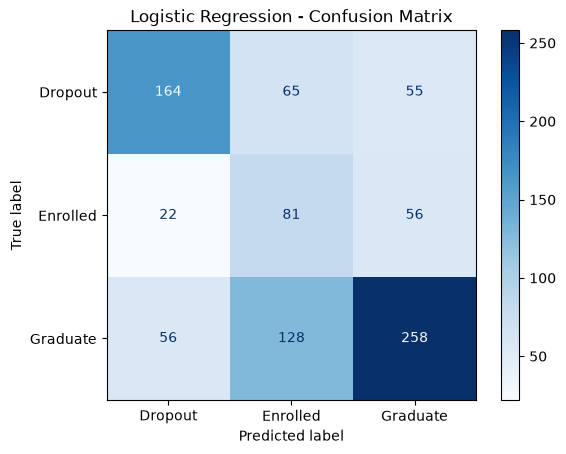

In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_pred = baseline_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Baseline Model Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=baseline_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=baseline_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


Random Forest Accuracy: 0.6181

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.61      0.64      0.63       284
    Enrolled       0.32      0.26      0.29       159
    Graduate       0.71      0.73      0.72       442

    accuracy                           0.62       885
   macro avg       0.55      0.55      0.55       885
weighted avg       0.61      0.62      0.61       885



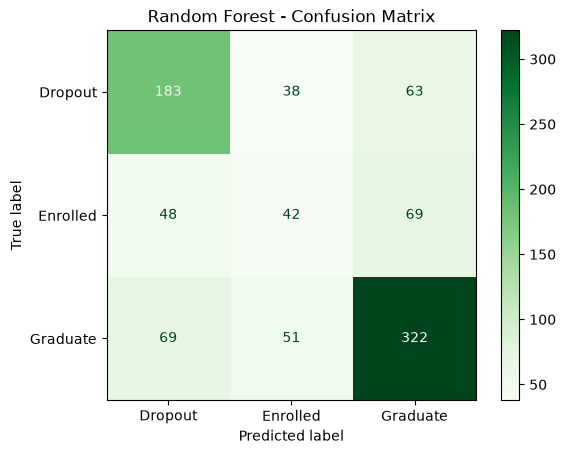

In [20]:
# Generate Random Forest predictions
rf_predictions = random_forest_model.predict(X_test)

# Evaluate performance
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", round(rf_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

# Confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=random_forest_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=random_forest_model.classes_
)

disp.plot(cmap="Greens", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": baseline_model,
    "Random Forest": random_forest_model
}

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Weighted F1": scores["test_f1_weighted"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(4)

,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.6019,0.5665,0.6153
1,Random Forest,0.6380,0.5638,0.6283


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

# Give the minority classes greater importance
class_weights = {
    "Dropout": 1.0,
    "Enrolled": 2.0,
    "Graduate": 1.0
}

weighted_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=class_weights,
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    weighted_rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted"
    },
    n_jobs=-1
)

print("Weighted Random Forest Results")
print("Accuracy:", round(scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(scores["test_f1_macro"].mean(), 4))
print("Weighted F1:", round(scores["test_f1_weighted"].mean(), 4))

Weighted Random Forest Results
Accuracy: 0.6485
Macro F1: 0.5561
Weighted F1: 0.6281


In [23]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

extra_trees_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

extra_scores = cross_validate(
    extra_trees_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted"
    },
    n_jobs=-1
)

print("Extra Trees Results")
print("Accuracy:", round(extra_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(extra_scores["test_f1_macro"].mean(), 4))
print("Weighted F1:", round(extra_scores["test_f1_weighted"].mean(), 4))

Extra Trees Results
Accuracy: 0.6448
Macro F1: 0.5356
Weighted F1: 0.6156


In [24]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold

# Encode target labels as integers for XGBoost
target_mapping = {
    "Dropout": 0,
    "Enrolled": 1,
    "Graduate": 2
}

y_train_encoded = y_train.map(target_mapping)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_scores = cross_validate(
    xgb_model,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted"
    },
    n_jobs=1
)

print("XGBoost Results")
print("Accuracy:", round(xgb_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(xgb_scores["test_f1_macro"].mean(), 4))
print("Weighted F1:", round(xgb_scores["test_f1_weighted"].mean(), 4))

XGBoost Results
Accuracy: 0.6635
Macro F1: 0.56
Weighted F1: 0.636


In [25]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_cv_predictions = cross_val_predict(
    xgb_model,
    X_train,
    y_train_encoded,
    cv=cv,
    n_jobs=1
)

reverse_mapping = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate"
}

xgb_cv_predictions_labels = pd.Series(
    xgb_cv_predictions
).map(reverse_mapping)

print(classification_report(
    y_train,
    xgb_cv_predictions_labels,
    zero_division=0
))

              precision    recall  f1-score   support

     Dropout       0.68      0.61      0.65      1137
    Enrolled       0.46      0.20      0.28       635
    Graduate       0.68      0.87      0.76      1767

    accuracy                           0.66      3539
   macro avg       0.61      0.56      0.56      3539
weighted avg       0.64      0.66      0.64      3539



In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Give the Enrolled class more importance
sample_weights = y_train_encoded.map({
    0: 1.0,
    1: 2.5,
    2: 1.0
})

weighted_xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

weighted_xgb_scores = cross_validate(
    weighted_xgb_model,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted"
    },
    params={"classifier__sample_weight": sample_weights},
    n_jobs=1
)

print("Weighted XGBoost")
print("Accuracy:", weighted_xgb_scores["test_accuracy"].mean())
print("Macro F1:", weighted_xgb_scores["test_f1_macro"].mean())
print("Weighted F1:", weighted_xgb_scores["test_f1_weighted"].mean())

In [28]:
print("Weighted XGBoost Results")
print("Accuracy:", round(weighted_xgb_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(weighted_xgb_scores["test_f1_macro"].mean(), 4))
print("Weighted F1:", round(weighted_xgb_scores["test_f1_weighted"].mean(), 4))

Weighted XGBoost Results
Accuracy: 0.636
Macro F1: 0.5926
Weighted F1: 0.6432


In [29]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

weighted_xgb_predictions = cross_val_predict(
    weighted_xgb_model,
    X_train,
    y_train_encoded,
    cv=cv,
    params={"classifier__sample_weight": sample_weights},
    n_jobs=1
)

weighted_xgb_predictions_labels = pd.Series(
    weighted_xgb_predictions
).map(reverse_mapping)

print(classification_report(
    y_train,
    weighted_xgb_predictions_labels,
    zero_division=0
))

              precision    recall  f1-score   support

     Dropout       0.76      0.53      0.62      1137
    Enrolled       0.35      0.51      0.42       635
    Graduate       0.73      0.75      0.74      1767

    accuracy                           0.64      3539
   macro avg       0.61      0.60      0.59      3539
weighted avg       0.67      0.64      0.64      3539



In [30]:
admission_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Weighted Random Forest",
        "Extra Trees",
        "XGBoost",
        "Weighted XGBoost"
    ],
    "Accuracy": [
        0.6019, 0.6380, 0.6485, 0.6448, 0.6635, 0.6360
    ],
    "Macro F1": [
        0.5665, 0.5638, 0.5561, 0.5356, 0.5600, 0.5926
    ],
    "Weighted F1": [
        0.6153, 0.6283, 0.6281, 0.6156, 0.6360, 0.6432
    ]
})

admission_model_comparison.sort_values(
    by="Macro F1", ascending=False
)

,Model,Accuracy,Macro F1,Weighted F1
5,Weighted XGBoost,0.6360,0.5926,0.6432
0,Logistic Regression,0.6019,0.5665,0.6153
1,Random Forest,0.6380,0.5638,0.6283
4,XGBoost,0.6635,0.5600,0.6360
2,Weighted Random Forest,0.6485,0.5561,0.6281
3,Extra Trees,0.6448,0.5356,0.6156


## 4. First-semester model comparison and held-out evaluation

Use the same train/test row indices as the admission-time experiment so the two prediction stages can be compared fairly. The model comparison uses only admission-time and first-semester predictors. The selected weighted Random Forest gives the `Enrolled` class extra weight.

In [31]:
# First-semester prediction dataset

X_first = df[first_semester_prediction_features].copy()
y_first = df["Target"].copy()

# Reuse exactly the same train/test row indices
X_first_train = X_first.loc[X_train.index]
X_first_test = X_first.loc[X_test.index]

y_first_train = y_first.loc[y_train.index]
y_first_test = y_first.loc[y_test.index]

print("First-semester dataset ready!")
print("Training shape:", X_first_train.shape)
print("Testing shape:", X_first_test.shape)

assert X_first_train.index.equals(X_train.index)
assert X_first_test.index.equals(X_test.index)

print("Train/test alignment verified!")

First-semester dataset ready!
Training shape: (3539, 30)
Testing shape: (885, 30)
Train/test alignment verified!


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# First-semester numerical features
first_semester_numerical_features = (
    numerical_features_admission
    + [
        "Curricular units 1st sem (credited)",
        "Curricular units 1st sem (enrolled)",
        "Curricular units 1st sem (evaluations)",
        "Curricular units 1st sem (approved)",
        "Curricular units 1st sem (grade)",
        "Curricular units 1st sem (without evaluations)"
    ]
)

first_semester_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), first_semester_numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ]
)

print("First-semester preprocessor created!")
print("Numerical features:", len(first_semester_numerical_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))

First-semester preprocessor created!
Numerical features: 12
Categorical features: 10
Binary features: 8


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Encode target labels
target_mapping = {
    "Dropout": 0,
    "Enrolled": 1,
    "Graduate": 2
}

y_first_train_encoded = y_first_train.map(target_mapping)

# Cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models
first_semester_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", first_semester_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", first_semester_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", first_semester_preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Evaluate models
first_semester_results = []

for name, model in first_semester_models.items():
    scores = cross_validate(
        model,
        X_first_train,
        y_first_train_encoded,
        cv=cv,
        scoring=["accuracy", "f1_macro", "f1_weighted"],
        n_jobs=1
    )

    first_semester_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Weighted F1": scores["test_f1_weighted"].mean()
    })

first_semester_comparison = pd.DataFrame(
    first_semester_results
).sort_values("Macro F1", ascending=False)

first_semester_comparison.round(4)

,Model,Accuracy,Macro F1,Weighted F1
1,Random Forest,0.7437,0.6823,0.7389
2,XGBoost,0.7604,0.6821,0.7471
0,Logistic Regression,0.7222,0.6801,0.7308


In [34]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

best_first_model = first_semester_models["Random Forest"]

first_rf_predictions = cross_val_predict(
    best_first_model,
    X_first_train,
    y_first_train_encoded,
    cv=cv,
    n_jobs=1
)

reverse_mapping = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate"
}

first_rf_predictions_labels = pd.Series(
    first_rf_predictions
).map(reverse_mapping)

print(classification_report(
    y_first_train,
    first_rf_predictions_labels,
    zero_division=0
))

              precision    recall  f1-score   support

     Dropout       0.78      0.73      0.76      1137
    Enrolled       0.50      0.43      0.46       635
    Graduate       0.79      0.86      0.83      1767

    accuracy                           0.74      3539
   macro avg       0.69      0.68      0.68      3539
weighted avg       0.74      0.74      0.74      3539



In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import classification_report

weighted_first_rf = Pipeline([
    ("preprocessor", first_semester_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight={
            "Dropout": 1.0,
            "Enrolled": 2.0,
            "Graduate": 1.0
        },
        random_state=42,
        n_jobs=-1
    ))
])

weighted_first_rf_scores = cross_validate(
    weighted_first_rf,
    X_first_train,
    y_first_train,
    cv=cv,
    scoring=["accuracy", "f1_macro", "f1_weighted"],
    n_jobs=1
)

print("Weighted First-Semester Random Forest")
print("Accuracy:", round(weighted_first_rf_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(weighted_first_rf_scores["test_f1_macro"].mean(), 4))
print("Weighted F1:", round(weighted_first_rf_scores["test_f1_weighted"].mean(), 4))

Weighted First-Semester Random Forest
Accuracy: 0.7519
Macro F1: 0.6845
Weighted F1: 0.7424


In [36]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Fit admission-time candidate
admission_final_model = weighted_xgb_model
admission_final_model.fit(X_train, y_train_encoded)

admission_predictions = admission_final_model.predict(X_test)
admission_predictions = pd.Series(admission_predictions).map(reverse_mapping)

print("ADMISSION-TIME MODEL")
print("Accuracy:", accuracy_score(y_test, admission_predictions))
print("Macro F1:", f1_score(y_test, admission_predictions, average="macro"))
print(classification_report(y_test, admission_predictions, zero_division=0))


# Fit first-semester candidate
first_final_model = weighted_first_rf
first_final_model.fit(X_first_train, y_first_train)

first_predictions = first_final_model.predict(X_first_test)

print("\nFIRST-SEMESTER MODEL")
print("Accuracy:", accuracy_score(y_first_test, first_predictions))
print("Macro F1:", f1_score(y_first_test, first_predictions, average="macro"))
print(classification_report(y_first_test, first_predictions, zero_division=0))

ADMISSION-TIME MODEL
Accuracy: 0.6463276836158192
Macro F1: 0.5250061390764907
              precision    recall  f1-score   support

     Dropout       0.66      0.63      0.64       284
    Enrolled       0.33      0.13      0.18       159
    Graduate       0.68      0.85      0.75       442

    accuracy                           0.65       885
   macro avg       0.55      0.53      0.53       885
weighted avg       0.61      0.65      0.61       885


FIRST-SEMESTER MODEL
Accuracy: 0.7254237288135593
Macro F1: 0.6488239888383519
              precision    recall  f1-score   support

     Dropout       0.77      0.65      0.71       284
    Enrolled       0.45      0.37      0.41       159
    Graduate       0.78      0.90      0.83       442

    accuracy                           0.73       885
   macro avg       0.66      0.64      0.65       885
weighted avg       0.71      0.73      0.72       885



## 5. SHAP explanations and symbolic reasoning

SHAP values are calculated for a sample of held-out first-semester records. Summary plots show class-specific contributions; the table aggregates absolute contribution across classes. The symbolic rules are fixed, readable indicators that complement model probabilities and do not constitute causal explanations or recommendations.

In [37]:
import shap
import numpy as np
import pandas as pd

# Extract fitted preprocessing and classifier
fitted_preprocessor = first_final_model.named_steps["preprocessor"]
fitted_classifier = first_final_model.named_steps["classifier"]

# Transform test data
X_test_transformed = fitted_preprocessor.transform(X_first_test)

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Convert to dense array for SHAP
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_first_test.index
)

# Select a small sample for explanations
X_shap_sample = X_test_transformed_df.sample(
    n=min(100, len(X_test_transformed_df)),
    random_state=42
)

# Calculate SHAP values
explainer = shap.TreeExplainer(fitted_classifier)
shap_values = explainer.shap_values(X_shap_sample)

print("SHAP analysis completed!")
print("Sample shape:", X_shap_sample.shape)
print("SHAP output type:", type(shap_values))

SHAP analysis completed!
Sample shape: (100, 237)
SHAP output type: <class 'numpy.ndarray'>


In [38]:
print("SHAP shape:", np.array(shap_values).shape)
print("Feature count:", len(feature_names))
print("Classes:", fitted_classifier.classes_)

SHAP shape: (100, 237, 3)
Feature count: 237
Classes: ['Dropout' 'Enrolled' 'Graduate']



SHAP importance: Dropout


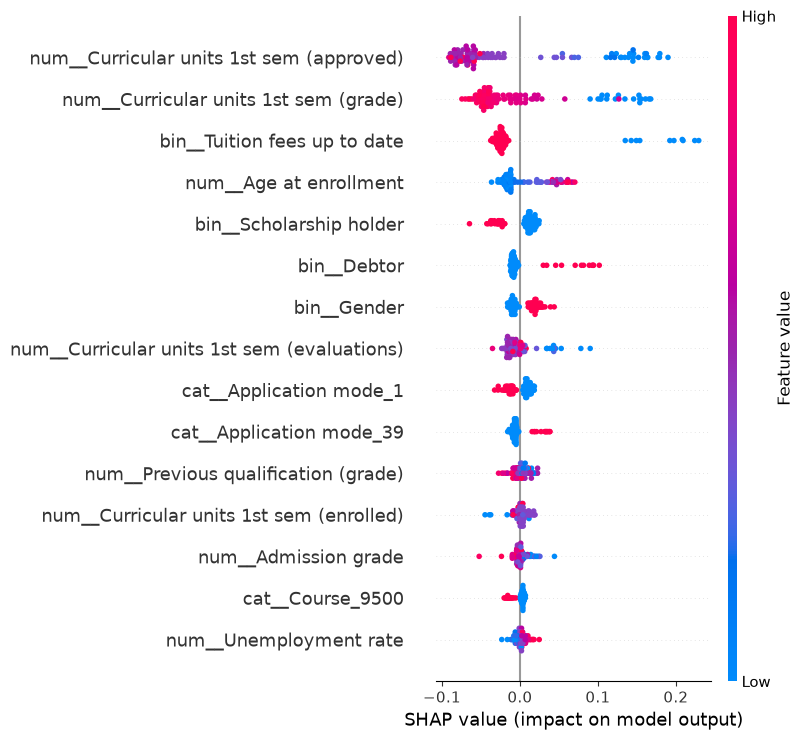


SHAP importance: Enrolled


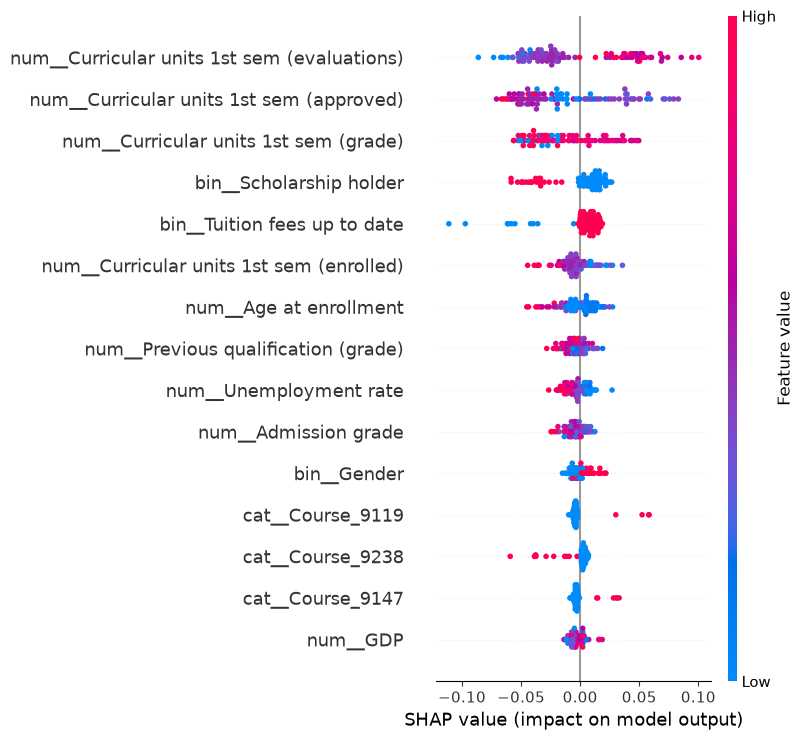


SHAP importance: Graduate


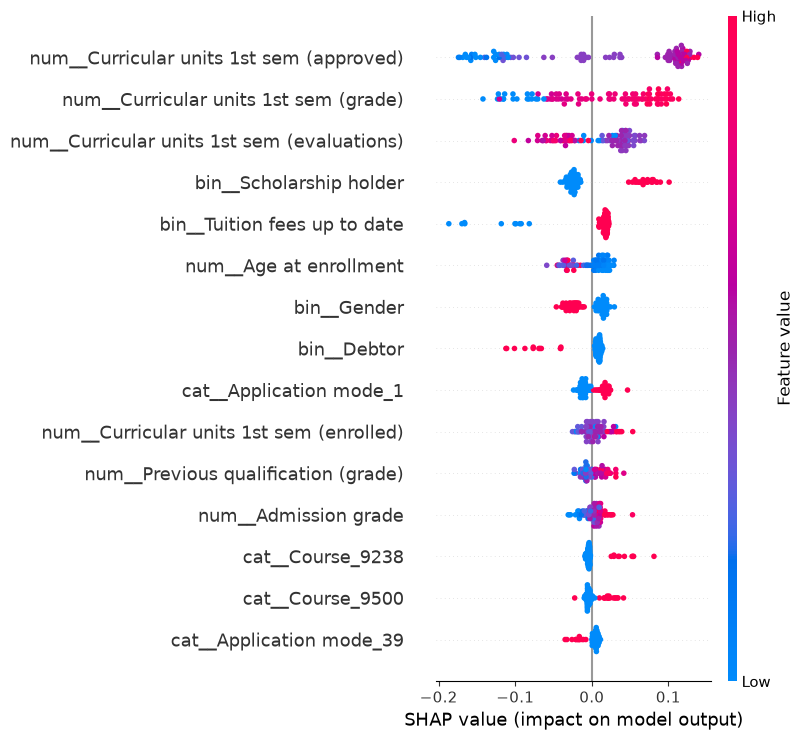

In [39]:
# Global SHAP feature importance for each outcome

for class_index, class_name in enumerate(fitted_classifier.classes_):

    print(f"\nSHAP importance: {class_name}")

    shap.summary_plot(
        shap_values[:, :, class_index],
        X_shap_sample,
        max_display=15,
        show=True
    )

In [40]:
# Mean absolute SHAP importance across all classes

global_shap_importance = np.abs(shap_values).mean(axis=(0, 2))

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": global_shap_importance
}).sort_values("Importance", ascending=False)

display(shap_importance_df.head(20))

,Feature,Importance
9,num__Curricular units 1st sem (approved),0.074326
10,num__Curricular units 1st sem (grade),0.048991
8,num__Curricular units 1st sem (evaluations),0.031405
233,bin__Tuition fees up to date,0.027281
235,bin__Scholarship holder,0.023216
2,num__Age at enrollment,0.018497
234,bin__Gender,0.013457
232,bin__Debtor,0.012063
18,cat__Application mode_1,0.009947
7,num__Curricular units 1st sem (enrolled),0.009445


In [41]:
def generate_student_reasoning(student):
    """
    Generate transparent academic risk indicators
    from first-semester student information.
    """

    reasons = []

    approved = student["Curricular units 1st sem (approved)"]
    grade = student["Curricular units 1st sem (grade)"]
    evaluations = student["Curricular units 1st sem (evaluations)"]
    enrolled = student["Curricular units 1st sem (enrolled)"]

    if approved <= 2:
        reasons.append(
            "Critical academic concern: very few first-semester units approved."
        )

    if grade < 8:
        reasons.append(
            "Academic concern: first-semester grade is below 8."
        )

    if enrolled > 0 and approved / enrolled < 0.5:
        reasons.append(
            "Academic concern: fewer than half of enrolled units were approved."
        )

    if evaluations > 0 and approved == 0:
        reasons.append(
            "Academic concern: evaluations occurred but no units were approved."
        )

    if student["Debtor"] == 1:
        reasons.append(
            "Financial indicator: student has an outstanding debt."
        )

    if student["Tuition fees up to date"] == 0:
        reasons.append(
            "Financial indicator: tuition fees are not up to date."
        )

    if not reasons:
        reasons.append(
            "No warning indicators were triggered by the current rules."
        )

    return reasons

In [42]:
def explain_student_prediction(student):
    """
    Combine ML prediction, SHAP explanation,
    and symbolic reasoning.
    """

    # Convert student data into DataFrame
    student_df = pd.DataFrame([student])

    # ML prediction
    prediction = first_final_model.predict(student_df)[0]

    probabilities = first_final_model.predict_proba(student_df)[0]

    probability_df = pd.DataFrame({
        "Outcome": first_final_model.classes_,
        "Probability": probabilities
    }).sort_values("Probability", ascending=False)

    # SHAP explanation
    transformed_student = fitted_preprocessor.transform(student_df)

    if hasattr(transformed_student, "toarray"):
        transformed_student = transformed_student.toarray()

    student_shap = explainer.shap_values(
        pd.DataFrame(
            transformed_student,
            columns=feature_names
        )
    )

    predicted_class_index = list(
        fitted_classifier.classes_
    ).index(prediction)

    shap_values_student = student_shap[0, :, predicted_class_index]

    shap_explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP Value": shap_values_student
    })

    shap_explanation["Absolute Importance"] = (
        shap_explanation["SHAP Value"].abs()
    )

    shap_explanation = shap_explanation.sort_values(
        "Absolute Importance",
        ascending=False
    ).head(10)

    # Symbolic reasoning
    reasoning = generate_student_reasoning(student)

    return {
        "prediction": prediction,
        "probabilities": probability_df,
        "shap_explanation": shap_explanation,
        "reasoning": reasoning
    }


print("Integrated EduReason AI prediction function created!")

Integrated EduReason AI prediction function created!


In [43]:
# Select one student from the held-out test set
sample_student = X_first_test.iloc[0].to_dict()

# Generate integrated explanation
result = explain_student_prediction(sample_student)

print("Predicted outcome:", result["prediction"])

print("\nOutcome probabilities:")
display(result["probabilities"])

print("\nTop SHAP explanations:")
display(result["shap_explanation"])

print("\nSymbolic reasoning:")
for reason in result["reasoning"]:
    print("-", reason)

Predicted outcome: Graduate

Outcome probabilities:


,Outcome,Probability
2,Graduate,0.756667
0,Dropout,0.133333
1,Enrolled,0.110000



Top SHAP explanations:


,Feature,SHAP Value,Absolute Importance
9,num__Curricular units 1st sem (approved),0.118154,0.118154
10,num__Curricular units 1st sem (grade),0.097325,0.097325
8,num__Curricular units 1st sem (evaluations),0.052208,0.052208
159,cat__Mother's occupation_2,-0.026224,0.026224
198,cat__Father's occupation_10,-0.025174,0.025174
1,num__Admission grade,0.023282,0.023282
235,bin__Scholarship holder,-0.019164,0.019164
234,bin__Gender,-0.018825,0.018825
233,bin__Tuition fees up to date,0.018399,0.018399
0,num__Previous qualification (grade),0.017127,0.017127



Symbolic reasoning:
- No warning indicators were triggered by the current rules.


## 6. Export the first-semester model and metadata

The final cell writes the fitted preprocessing/model pipeline and its feature/class metadata to `models/`. Running the export cell overwrites those paths if files already exist. This cell was preserved but not executed during the reorganization.

In [44]:
import joblib
from pathlib import Path

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    first_final_model,
    MODEL_DIR / "first_semester_model.joblib"
)

joblib.dump(
    {
        "feature_names": first_semester_prediction_features,
        "classes": list(first_final_model.classes_),
        "target_mapping": target_mapping,
        "binary_features": binary_features,
        "categorical_features": categorical_features,
        "numerical_features": first_semester_numerical_features
    },
    MODEL_DIR / "model_metadata.joblib"
)

print("Model and metadata saved successfully!")

Model and metadata saved successfully!
